

# Modeling – Bike Sharing Dataset

## Introduktion

I denne notebook arbejdes der med Machine Learning til at forudsige antallet af cykeludlejninger pr. time.

Der bruges resultater fra EDA til at vælge features og udvikle modeller.

Der trænes og sammenlignes forskellige regressionsmodeller for at finde den model, der giver de mest præcise forudsigelser.

Denne del af projektet tager udgangspunkt i Modeling og Evaluation fra CRISP-DM.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Indlæs datasættet fra EDA-projektet
csv_path = Path("data/hour.csv")

df = pd.read_csv(csv_path, parse_dates=["dteday"])

print("Datasættets størrelse:", df.shape)
display(df.head())

Datasættets størrelse: (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1



## 2. Feature Selection

Der udvælges 12 features, som skal bruges til at forudsige `cnt`.

`casual` og `registered` udelades, da de tilsammen giver det præcise antal udlejninger og derfor vil medføre data leakage.

`instant` og `dteday` fjernes også fra modellens input. Tidspunkt og dato er allerede repræsenteret gennem andre variabler.

Målvariablen er `cnt`.


In [3]:
# Variabler, vi ikke ønsker at bruge som input
drop_columns = [
    'instant',
    'dteday',
    'casual',
    'registered',
    'cnt'
]

# X indeholder vores features
X = df.drop(columns=drop_columns)

# y indeholder den værdi, vi vil forudsige
y = df['cnt']

print("Antal features:", X.shape[1])
print("Antal observationer:", X.shape[0])

display(X.head())

Antal features: 12
Antal observationer: 17379


,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed
0,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0
1,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0
2,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0
3,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0
4,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0



## 3. Train/Test Split

Data opdeles i 80 % træningsdata og 20 % testdata.

Da datasættet indeholder tidsbaserede observationer, opdeles data kronologisk i stedet for tilfældigt.

Modellen trænes dermed på ældre data og testes på nyere data.


In [4]:
# Sortér data kronologisk
df = df.sort_values(
    by=['dteday', 'hr']
).reset_index(drop=True)

# Vælg features og målvariabel igen efter sortering
X = df.drop(columns=[
    'instant',
    'dteday',
    'casual',
    'registered',
    'cnt'
])

y = df['cnt']

# 80 % træning og 20 % test
split_index = int(len(df) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Træningsdata:", X_train.shape)
print("Testdata:", X_test.shape)

print("\nTræningsperiode:")
print(df['dteday'].iloc[0], "til",
      df['dteday'].iloc[split_index - 1])

print("\nTestperiode:")
print(df['dteday'].iloc[split_index], "til",
      df['dteday'].iloc[-1])

Træningsdata: (13903, 12)
Testdata: (3476, 12)

Træningsperiode:
2011-01-01 00:00:00 til 2012-08-07 00:00:00

Testperiode:
2012-08-07 00:00:00 til 2012-12-31 00:00:00



## 4. Baseline-model

Først oprettes en simpel baseline med DummyRegressor.

Modellen forudsiger altid gennemsnittet fra træningsdata.

Resultaterne bruges som sammenligningsgrundlag for de øvrige modeller.

Modellerne evalueres med MAE, RMSE og R².


In [6]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Opret baseline-model
baseline = DummyRegressor(strategy="mean")

# Træn modellen på træningsdata
baseline.fit(X_train, y_train)

# Lav forudsigelser på testdata
y_pred_baseline = baseline.predict(X_test)

# Beregn evalueringsmål
baseline_mae = mean_absolute_error(y_test, y_pred_baseline)
baseline_rmse = np.sqrt(mean_squared_error(y_test, y_pred_baseline))
baseline_r2 = r2_score(y_test, y_pred_baseline)

print("Baseline-model resultater:")
print(f"MAE: {baseline_mae:.2f}")
print(f"RMSE: {baseline_rmse:.2f}")
print(f"R²: {baseline_r2:.3f}")

Baseline-model resultater:
MAE: 174.98
RMSE: 232.61
R²: -0.113



### Resultat

Baseline-modellen opnåede en MAE på 174,98, RMSE på 232,61 og R² på -0,113.

Den negative R² viser, at modellen klarer sig dårligere end en konstant forudsigelse baseret på gennemsnittet af testdata.



## 5. Linear Regression

Linear Regression bruges som den første egentlige ML-model.

Modellen forsøger at finde lineære sammenhænge mellem de udvalgte features og antallet af cykeludlejninger.

Resultaterne sammenlignes med baseline.


In [7]:
from sklearn.linear_model import LinearRegression

# Opret Linear Regression-model
linear_model = LinearRegression()

# Træn modellen
linear_model.fit(X_train, y_train)

# Lav forudsigelser på testdata
y_pred_linear = linear_model.predict(X_test)

# Evaluer modellen
linear_mae = mean_absolute_error(y_test, y_pred_linear)
linear_rmse = np.sqrt(mean_squared_error(y_test, y_pred_linear))
linear_r2 = r2_score(y_test, y_pred_linear)

print("Linear Regression resultater:")
print(f"MAE: {linear_mae:.2f}")
print(f"RMSE: {linear_rmse:.2f}")
print(f"R²: {linear_r2:.3f}")

Linear Regression resultater:
MAE: 138.29
RMSE: 183.28
R²: 0.309



### Resultat

Linear Regression opnåede en MAE på 138,29, RMSE på 183,28 og R² på 0,309.

Modellen klarer sig bedre end baseline, men har stadig forholdsvis store forudsigelsesfejl.



## 6. Random Forest

Random Forest bruger flere decision trees til at lave forudsigelser.

Modellen kan lære mere komplekse sammenhænge end Linear Regression og undersøges derfor som et alternativ.


In [8]:
from sklearn.ensemble import RandomForestRegressor

# Opret Random Forest-modellen
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

# Træn modellen
rf_model.fit(X_train, y_train)

# Lav forudsigelser
y_pred_rf = rf_model.predict(X_test)

# Evaluer modellen
rf_mae = mean_absolute_error(y_test, y_pred_rf)
rf_rmse = np.sqrt(mean_squared_error(y_test, y_pred_rf))
rf_r2 = r2_score(y_test, y_pred_rf)

print("Random Forest resultater:")
print(f"MAE: {rf_mae:.2f}")
print(f"RMSE: {rf_rmse:.2f}")
print(f"R²: {rf_r2:.3f}")

Random Forest resultater:
MAE: 45.13
RMSE: 69.87
R²: 0.900



### Resultat

Random Forest opnåede en MAE på 45,13, RMSE på 69,87 og R² på 0,900.

Det er en tydelig forbedring sammenlignet med Linear Regression. Modellen ser derfor ud til at håndtere datasættets mere komplekse mønstre bedre.



## 7. Gradient Boosting

Gradient Boosting bruger også decision trees, men bygger dem efter hinanden.

Hvert nyt træ forsøger at reducere fejlene fra de tidligere træer.

Modellen trænes for at sammenligne dens resultater med Random Forest.


In [9]:
from sklearn.ensemble import GradientBoostingRegressor

# Opret Gradient Boosting-modellen
gb_model = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

# Træn modellen
gb_model.fit(X_train, y_train)

# Lav forudsigelser
y_pred_gb = gb_model.predict(X_test)

# Evaluer modellen
gb_mae = mean_absolute_error(y_test, y_pred_gb)
gb_rmse = np.sqrt(mean_squared_error(y_test, y_pred_gb))
gb_r2 = r2_score(y_test, y_pred_gb)

print("Gradient Boosting resultater:")
print(f"MAE: {gb_mae:.2f}")
print(f"RMSE: {gb_rmse:.2f}")
print(f"R²: {gb_r2:.3f}")

Gradient Boosting resultater:
MAE: 73.62
RMSE: 107.44
R²: 0.763



### Resultat

Gradient Boosting opnåede en MAE på 73,62, RMSE på 107,44 og R² på 0,763.

Modellen klarer sig bedre end Linear Regression, men ikke lige så godt som Random Forest med de valgte indstillinger.



## 8. Sammenligning af modeller

De fire modeller sammenlignes ved hjælp af MAE, RMSE og R².

Random Forest har den laveste MAE og RMSE samt den højeste R² og klarer sig dermed bedst i den indledende sammenligning.

Da testdata er brugt til denne sammenligning, er den senere evaluering ikke fuldstændig uafhængig af modelvalget.


In [10]:
# Sammenlign modellerne
model_results = pd.DataFrame({
    'Model': [
        'Baseline',
        'Linear Regression',
        'Random Forest',
        'Gradient Boosting'
    ],
    'MAE': [
        baseline_mae,
        linear_mae,
        rf_mae,
        gb_mae
    ],
    'RMSE': [
        baseline_rmse,
        linear_rmse,
        rf_rmse,
        gb_rmse
    ],
    'R2': [
        baseline_r2,
        linear_r2,
        rf_r2,
        gb_r2
    ]
})

# Sorter efter laveste MAE
model_results = model_results.sort_values(
    by='MAE'
).reset_index(drop=True)

display(model_results.round(3))

,Model,MAE,RMSE,R2
0,Random Forest,45.135,69.874,0.900
1,Gradient Boosting,73.617,107.438,0.763
2,Linear Regression,138.292,183.278,0.309
3,Baseline,174.985,232.608,-0.113



## 9. Feature Engineering

I EDA blev der fundet tydelige forskelle mellem arbejdsdage og fridage, særligt omkring myldretiden.

Derfor tilføjes en ny feature, `rush_hour`, som angiver, om der er tale om myldretid på en arbejdsdag.

Den nye feature undersøges for at se, om den forbedrer modellens forudsigelser.


In [11]:
# Lav kopier af trænings- og testdata
X_train_fe = X_train.copy()
X_test_fe = X_test.copy()

# Funktion til at identificere myldretid på arbejdsdage
def add_features(data):
    data = data.copy()

    data["rush_hour"] = (
        (data["workingday"] == 1) &
        (data["hr"].isin([7, 8, 9, 16, 17, 18]))
    ).astype(int)

    return data

# Tilføj den nye feature
X_train_fe = add_features(X_train_fe)
X_test_fe = add_features(X_test_fe)

print("Antal features før:", X_train.shape[1])
print("Antal features efter:", X_train_fe.shape[1])

display(X_train_fe.head(10))

Antal features før: 12
Antal features efter: 13


,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,rush_hour
0,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0000,0
1,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0000,0
2,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0000,0
3,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0000,0
4,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0000,0
5,1,0,1,5,0,6,0,2,0.24,0.2576,0.75,0.0896,0
6,1,0,1,6,0,6,0,1,0.22,0.2727,0.80,0.0000,0
7,1,0,1,7,0,6,0,1,0.20,0.2576,0.86,0.0000,0
8,1,0,1,8,0,6,0,1,0.24,0.2879,0.75,0.0000,0
9,1,0,1,9,0,6,0,1,0.32,0.3485,0.76,0.0000,0



## 10. Evaluering af Feature Engineering

Random Forest sammenlignes med og uden den nye `rush_hour`-feature.

Der bruges TimeSeriesSplit med fem opdelinger, så modellen trænes på tidligere observationer og valideres på senere observationer.

Testdata bruges ikke i denne sammenligning.


In [12]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, cross_validate
import pandas as pd

# Tidsbaseret cross-validation
tscv = TimeSeriesSplit(n_splits=5)

# Funktion til at evaluere Random Forest
def evaluate_features(X_data, y_data):
    model = RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )

    scores = cross_validate(
        model,
        X_data,
        y_data,
        cv=tscv,
        scoring={
            "MAE": "neg_mean_absolute_error",
            "RMSE": "neg_root_mean_squared_error"
        },
        n_jobs=1
    )

    return {
        "MAE": -scores["test_MAE"].mean(),
        "RMSE": -scores["test_RMSE"].mean()
    }

# Random Forest uden feature engineering
original_scores = evaluate_features(X_train, y_train)

# Random Forest med rush_hour
feature_scores = evaluate_features(X_train_fe, y_train)

# Sammenlign resultater
comparison = pd.DataFrame({
    "Model": [
        "Random Forest (12 features)",
        "Random Forest + rush_hour (13 features)"
    ],
    "MAE": [
        original_scores["MAE"],
        feature_scores["MAE"]
    ],
    "RMSE": [
        original_scores["RMSE"],
        feature_scores["RMSE"]
    ]
})

display(comparison.round(2))

,Model,MAE,RMSE
0,Random Forest (12 features),51.94,79.64
1,Random Forest + rush_hour (13 features),50.74,77.56



### Resultat

Random Forest med 12 features opnåede en gennemsnitlig MAE på 51,94 og RMSE på 79,64 under cross-validation.

Med `rush_hour` faldt MAE til 50,74 og RMSE til 77,56.

Den nye feature giver altså en mindre forbedring, og derfor beholdes den i den videre modeludvikling.



## 11. Hyperparameter Tuning

Random Forest optimeres med RandomizedSearchCV.

Der undersøges 15 kombinationer af hyperparametre med fem tidsbaserede valideringsopdelinger.

Der justeres blandt andet på antal træer, maksimal trædybde og minimum antal observationer ved opdeling.

Målet er at finde indstillingerne med den laveste MAE.


In [13]:
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.ensemble import RandomForestRegressor

# Opret Random Forest-model
rf_tuning = RandomForestRegressor(
    random_state=42,
    n_jobs=-1
)

# Hyperparametre, der skal undersøges
param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [10, 20, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

# Tidsbaseret cross-validation
tscv = TimeSeriesSplit(n_splits=5)

# Hyperparameter tuning
random_search = RandomizedSearchCV(
    estimator=rf_tuning,
    param_distributions=param_grid,
    n_iter=15,
    cv=tscv,
    scoring="neg_mean_absolute_error",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Træn og find de bedste indstillinger
random_search.fit(X_train_fe, y_train)

print("Bedste hyperparametre:")
print(random_search.best_params_)

print("\nBedste MAE fra cross-validation:")
print(round(-random_search.best_score_, 2))

Fitting 5 folds for each of 15 candidates, totalling 75 fits
Bedste hyperparametre:
{'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_depth': 20}

Bedste MAE fra cross-validation:
50.58



### Resultat

De bedste indstillinger var 200 træer, en maksimal dybde på 20, `min_samples_split` på 5 og `min_samples_leaf` på 1.

Den gennemsnitlige MAE blev 50,58 under cross-validation.

Det er en lille forbedring i forhold til modellen før tuning, som havde en MAE på 50,74.



## 12. Evaluering af den optimerede model

Den optimerede Random Forest evalueres på testdata med MAE, RMSE og R².

Resultaterne sammenlignes med den oprindelige Random Forest for at se effekten af feature engineering og tuning.


In [14]:
# Den bedste model fra RandomizedSearchCV
best_rf_model = random_search.best_estimator_

# Forudsig på testdata med den nye rush_hour-feature
y_pred_best_rf = best_rf_model.predict(X_test_fe)

# Beregn resultater
best_rf_mae = mean_absolute_error(y_test, y_pred_best_rf)
best_rf_rmse = np.sqrt(mean_squared_error(y_test, y_pred_best_rf))
best_rf_r2 = r2_score(y_test, y_pred_best_rf)

print("Optimeret Random Forest:")
print(f"MAE: {best_rf_mae:.2f}")
print(f"RMSE: {best_rf_rmse:.2f}")
print(f"R²: {best_rf_r2:.3f}")

# Sammenlign oprindelig og optimeret model
final_comparison = pd.DataFrame({
    "Model": [
        "Random Forest (oprindelig)",
        "Random Forest (optimeret)"
    ],
    "MAE": [rf_mae, best_rf_mae],
    "RMSE": [rf_rmse, best_rf_rmse],
    "R2": [rf_r2, best_rf_r2]
})

display(final_comparison.round(3))

Optimeret Random Forest:
MAE: 44.01
RMSE: 68.44
R²: 0.904


,Model,MAE,RMSE,R2
0,Random Forest (oprindelig),45.135,69.874,0.900
1,Random Forest (optimeret),44.014,68.438,0.904



### Resultat

Den optimerede Random Forest opnåede en MAE på 44,01, RMSE på 68,44 og R² på 0,904.

Det er en mindre forbedring i forhold til den oprindelige Random Forest, der havde en MAE på 45,13.

Da testdata tidligere blev brugt til modelsammenligning, skal resultatet dog fortolkes med det forbehold.



## 13. Feature Importance

Feature Importance bruges til at undersøge, hvilke variabler Random Forest lægger mest vægt på under træningen.


,Feature,Importance
3,hr,0.5040
12,rush_hour,0.1217
9,atemp,0.0912
8,temp,0.0760
1,yr,0.0759
6,workingday,0.0322
10,hum,0.0320
7,weathersit,0.0174
2,mnth,0.0150
0,season,0.0124


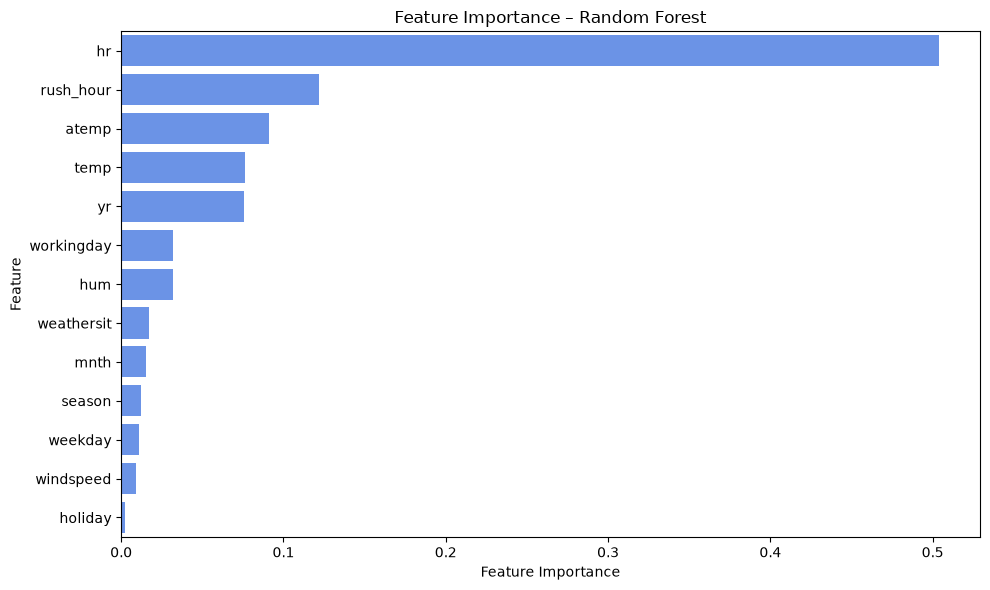

In [15]:
# Hent feature importance fra den optimerede Random Forest
importance = pd.DataFrame({
    "Feature": X_train_fe.columns,
    "Importance": best_rf_model.feature_importances_
})

# Sorter efter betydning
importance = importance.sort_values(
    by="Importance",
    ascending=False
)

display(importance.round(4))

# Visualisering
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance – Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()


### Resultat

Klokkeslæt (`hr`) har den højeste feature importance med 50,4 %.

Den nye feature `rush_hour` ligger nummer to med 12,17 %, efterfulgt af følt temperatur og temperatur.

Resultaterne passer godt med EDA, hvor særligt tidspunkt og myldretid viste tydelige mønstre.

Feature Importance viser dog ikke nødvendigvis, hvilke variabler der direkte forårsager ændringer i cykeludlejningen.



## 14. Analyse af forudsigelser og fejl

De faktiske og forudsagte udlejninger sammenlignes for at undersøge, hvor godt modellen rammer.

Der laves også et residualplot, som viser forskellen mellem de faktiske og forudsagte værdier.


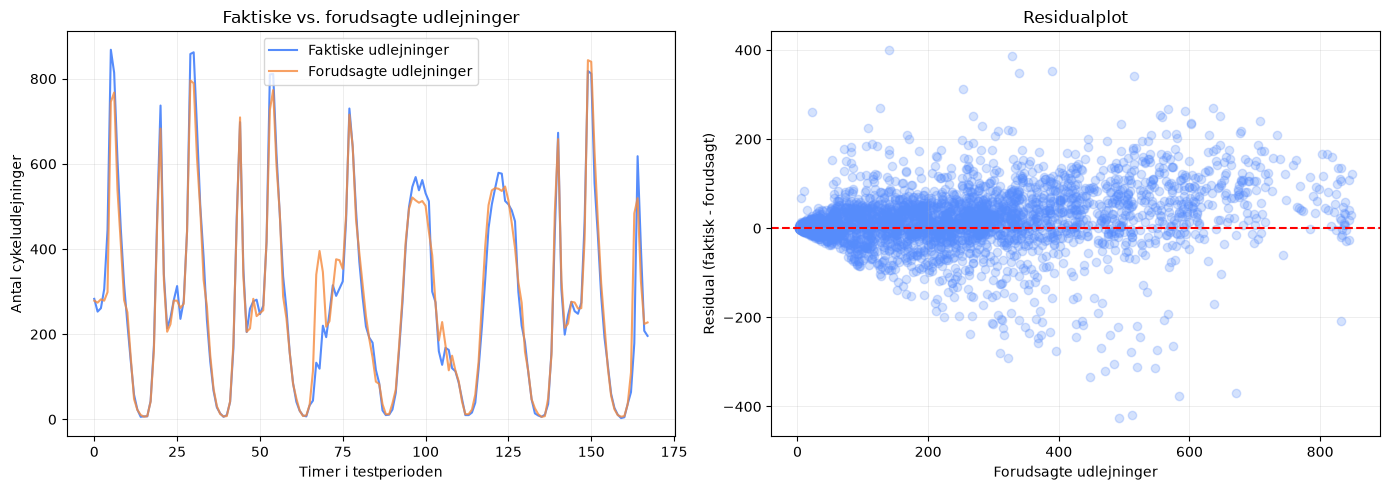

In [16]:
# Sammenligning af faktiske og forudsagte værdier
results = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred_best_rf
})

# Residualer: faktisk værdi minus forudsagt værdi
results["Residual"] = results["Actual"] - results["Predicted"]

fig, axs = plt.subplots(1, 2, figsize=(14, 5))

# Graf 1: Faktiske vs. forudsagte værdier
# Vi viser de første 168 timer (ca. en uge)
n = 168

axs[0].plot(
    results["Actual"].iloc[:n].to_numpy(),
    label="Faktiske udlejninger"
)

axs[0].plot(
    results["Predicted"].iloc[:n].to_numpy(),
    label="Forudsagte udlejninger",
    alpha=0.8
)

axs[0].set_title("Faktiske vs. forudsagte udlejninger")
axs[0].set_xlabel("Timer i testperioden")
axs[0].set_ylabel("Antal cykeludlejninger")
axs[0].legend()
axs[0].grid(alpha=0.3)

# Graf 2: Residualplot
axs[1].scatter(
    results["Predicted"],
    results["Residual"],
    alpha=0.25
)

axs[1].axhline(0, color="red", linestyle="--")
axs[1].set_title("Residualplot")
axs[1].set_xlabel("Forudsagte udlejninger")
axs[1].set_ylabel("Residual (faktisk - forudsagt)")
axs[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


### Resultat

Modellen følger generelt de faktiske udlejningstal godt og fanger de fleste aktivitetstoppe.

Residualplottet viser dog, at fejlene bliver mere spredte ved højere udlejningstal.

Det tyder på, at modellen har større vanskeligheder med at forudsige perioder med høj efterspørgsel.



## 15. Konklusion

Der er blevet trænet og sammenlignet fire forskellige regressionsmodeller.

Random Forest opnåede de bedste resultater. Efter feature engineering og hyperparameter tuning endte modellen med en MAE på 44,01, RMSE på 68,44 og R² på 0,904.

Feature Importance viste, at klokkeslæt og myldretid var blandt de vigtigste variabler.

Modellen følger generelt de faktiske udlejninger godt, men laver større fejl ved høje udlejningstal.

Samlet set viser resultaterne, at Random Forest fungerer godt til at forudsige cykeludlejningen i det undersøgte datasæt. Resultaterne skal dog ses med forbehold for den tidligere brug af testdata til modelsammenligning.
